In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing



housing = fetch_california_housing(as_frame=True)


df = housing.frame


df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nStatistical summary:")
df.describe()


Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (20640, 8)
Target shape: (20640,)

Feature columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [6]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)
print("Original testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Original training shape: (16512, 8)
Scaled training shape: (16512, 8)
Original testing shape: (4128, 8)
Scaled testing shape: (4128, 8)


In [7]:

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred_linear = linear_model.predict(X_test_scaled)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE:", round(mae_linear, 4))
print("MSE:", round(mse_linear, 4))
print("RMSE:", round(rmse_linear, 4))
print("R2 Score:", round(r2_linear, 4))


Linear Regression Results
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758


In [9]:

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("MAE:", round(mae_ridge, 4))
print("MSE:", round(mse_ridge, 4))
print("RMSE:", round(rmse_ridge, 4))
print("R2 Score:", round(r2_ridge, 4))


Ridge Regression Results
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758


In [10]:

from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42, max_depth=10)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mse_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("MAE:", round(mae_tree, 4))
print("MSE:", round(mse_tree, 4))
print("RMSE:", round(rmse_tree, 4))
print("R2 Score:", round(r2_tree, 4))


Decision Tree Results
MAE: 0.4335
MSE: 0.4165
RMSE: 0.6454
R2 Score: 0.6822


In [11]:

results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Decision Tree"],
    "MAE": [mae_linear, mae_ridge, mae_tree],
    "MSE": [mse_linear, mse_ridge, mse_tree],
    "RMSE": [rmse_linear, rmse_ridge, rmse_tree],
    "R2 Score": [r2_linear, r2_ridge, r2_tree]
})

results = results.round(4)

results


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.5332,0.5559,0.7456,0.5758
1,Ridge Regression,0.5332,0.5559,0.7456,0.5758
2,Decision Tree,0.4335,0.4165,0.6454,0.6822


In [12]:

from sklearn.linear_model import Ridge

alpha_values = [0.01, 0.1, 1, 10, 100]
ridge_results = []

for alpha in alpha_values:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    
    predictions = model.predict(X_test_scaled)
    
    ridge_results.append({
        "Alpha": alpha,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

ridge_comparison = pd.DataFrame(ridge_results)
ridge_comparison = ridge_comparison.round(4)

ridge_comparison


,Alpha,MAE,RMSE,R2 Score
0,0.01,0.5332,0.7456,0.5758
1,0.10,0.5332,0.7456,0.5758
2,1.00,0.5332,0.7456,0.5758
3,10.00,0.5331,0.7453,0.5761
4,100.00,0.5330,0.7438,0.5778


In [13]:

best_ridge_row = ridge_comparison.loc[ridge_comparison["RMSE"].idxmin()]

print("Best Alpha:", best_ridge_row["Alpha"])
print("Lowest RMSE:", best_ridge_row["RMSE"])
print("MAE:", best_ridge_row["MAE"])
print("R2 Score:", best_ridge_row["R2 Score"])


Best Alpha: 100.0
Lowest RMSE: 0.7438
MAE: 0.533
R2 Score: 0.5778


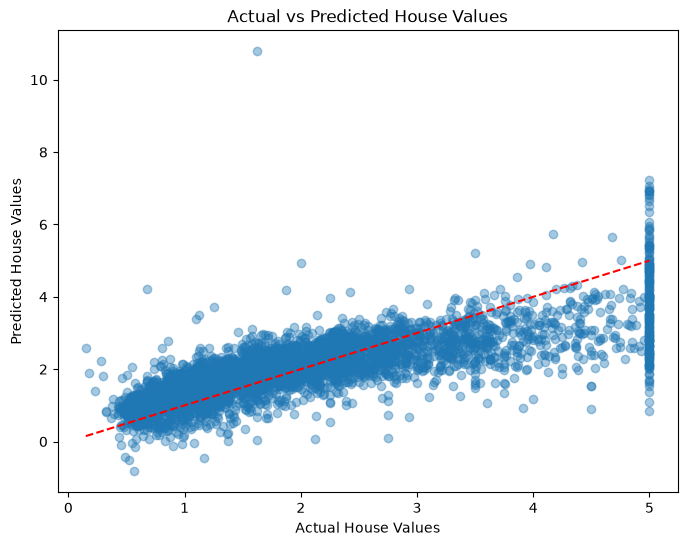

In [14]:

best_alpha = best_ridge_row["Alpha"]

best_ridge_model = Ridge(alpha=best_alpha)
best_ridge_model.fit(X_train_scaled, y_train)

y_pred_best_ridge = best_ridge_model.predict(X_test_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best_ridge, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")
plt.show()


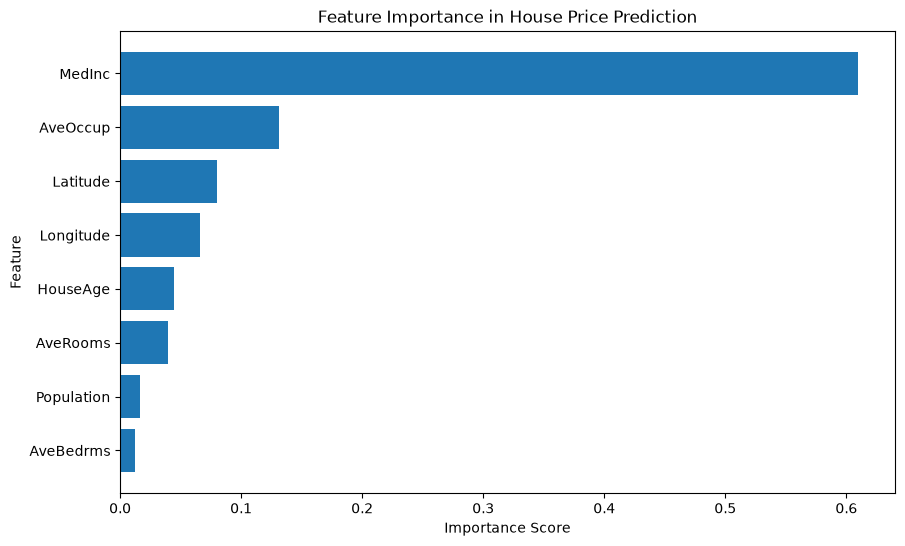

,Feature,Importance
0,MedInc,0.609784
5,AveOccup,0.130875
6,Latitude,0.079963
7,Longitude,0.066373
1,HouseAge,0.044366
2,AveRooms,0.039435
4,Population,0.016597
3,AveBedrms,0.012608


In [15]:

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree_model.feature_importances_
})

importance = importance.sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Feature Importance in House Price Prediction")
plt.gca().invert_yaxis()
plt.show()

importance


In [16]:

df_engineered = df.copy()

df_engineered["RoomsPerHousehold"] = df_engineered["AveRooms"] / df_engineered["AveOccup"]
df_engineered["BedroomsPerRoom"] = df_engineered["AveBedrms"] / df_engineered["AveRooms"]
df_engineered["PopulationPerHousehold"] = df_engineered["Population"] / df_engineered["AveOccup"]

df_engineered[[
    "AveRooms",
    "AveBedrms",
    "AveOccup",
    "RoomsPerHousehold",
    "BedroomsPerRoom",
    "PopulationPerHousehold"
]].head()


,AveRooms,AveBedrms,AveOccup,RoomsPerHousehold,BedroomsPerRoom,PopulationPerHousehold
0,6.984127,1.023810,2.555556,2.732919,0.146591,126.0
1,6.238137,0.971880,2.109842,2.956685,0.155797,1138.0
2,8.288136,1.073446,2.802260,2.957661,0.129516,177.0
3,5.817352,1.073059,2.547945,2.283154,0.184458,219.0
4,6.281853,1.081081,2.181467,2.879646,0.172096,259.0


In [17]:

X_new = df_engineered.drop("MedHouseVal", axis=1)
y_new = df_engineered["MedHouseVal"]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2, random_state=42
)

scaler_new = StandardScaler()

X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

engineered_model = LinearRegression()
engineered_model.fit(X_train_new_scaled, y_train_new)

y_pred_engineered = engineered_model.predict(X_test_new_scaled)

print("Original Linear Regression R2:", round(r2_linear, 4))
print("Engineered Features R2:", round(r2_score(y_test_new, y_pred_engineered), 4))
print("Engineered Features MAE:", round(mean_absolute_error(y_test_new, y_pred_engineered), 4))
print("Engineered Features RMSE:", round(np.sqrt(mean_squared_error(y_test_new, y_pred_engineered)), 4))


Original Linear Regression R2: 0.5758
Engineered Features R2: 0.6535
Engineered Features MAE: 0.4874
Engineered Features RMSE: 0.6738


In [18]:

feature_comparison = pd.DataFrame({
    "Model": ["Original Linear Regression", "Linear Regression with Engineered Features"],
    "MAE": [mae_linear, mean_absolute_error(y_test_new, y_pred_engineered)],
    "RMSE": [rmse_linear, np.sqrt(mean_squared_error(y_test_new, y_pred_engineered))],
    "R2 Score": [r2_linear, r2_score(y_test_new, y_pred_engineered)]
})

feature_comparison.round(4)


,Model,MAE,RMSE,R2 Score
0,Original Linear Regression,0.5332,0.7456,0.5758
1,Linear Regression with Engineered Features,0.4874,0.6738,0.6535


In [19]:

final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Linear Regression with Engineered Features"
    ],
    "MAE": [
        mae_linear,
        mae_ridge,
        mae_tree,
        mean_absolute_error(y_test_new, y_pred_engineered)
    ],
    "RMSE": [
        rmse_linear,
        rmse_ridge,
        rmse_tree,
        np.sqrt(mean_squared_error(y_test_new, y_pred_engineered))
    ],
    "R2 Score": [
        r2_linear,
        r2_ridge,
        r2_tree,
        r2_score(y_test_new, y_pred_engineered)
    ]
})

final_comparison = final_comparison.sort_values("R2 Score", ascending=False)
final_comparison.round(4)


,Model,MAE,RMSE,R2 Score
2,Decision Tree,0.4335,0.6454,0.6822
3,Linear Regression with Engineered Features,0.4874,0.6738,0.6535
1,Ridge Regression,0.5332,0.7456,0.5758
0,Linear Regression,0.5332,0.7456,0.5758


## Conclusion

In this project, the California Housing dataset was used to develop and evaluate machine learning models for house value prediction.

The dataset was explored to understand its features, data types, missing values, and statistical properties. The data was divided into training and testing sets, and feature scaling was applied to support the regression models.

Three regression algorithms were implemented: Linear Regression, Ridge Regression, and Decision Tree Regression. Their performance was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score.

Ridge Regression was optimized by testing different alpha values. Actual vs. predicted values were visualized, and Decision Tree feature importance was examined to understand the contribution of individual features.

Feature engineering was also performed by creating additional variables related to rooms, bedrooms, and population per household. The resulting model was compared with the original Linear Regression model to evaluate the effect of the engineered features.

Finally, the models were compared using their evaluation metrics to identify the most suitable model based on prediction accuracy. This project demonstrates how preprocessing, feature engineering, model optimization, and performance evaluation can be applied to a real-world regression problem.
